# Getting started with `morec`

`morec` builds **reduced-order models (ROMs) of impurity Green's functions** by combining

* **eigenvector continuation (EC)**: a basis $\mathcal{B}$ of $k$ exact ground states represents
  the ground state $|\Psi(\vec p)\rangle \approx \mathcal{B}\varphi(\vec p)$ across a parameter
  domain, through a $k\times k$ eigenproblem;
* **model order reduction (MOR)**: projectors $\mathbf V$ built from resolvent snapshots at $r$
  interpolation frequencies reduce the particle and hole resolvents to $m\times m$ matrices
  ($m \lesssim kr \ll d$).

The ROM is **built once** (offline, optionally enriched online during a coarse DMFT sweep) and then
**used for many impurity solves**, each of which involves only $k\times k$ and $m\times m$ matrices.

The models here are tiny so that everything can be checked against exact diagonalization (ED).  ED
is fast at these sizes, so a ROM solve is a few times cheaper, not orders of magnitude; the gain
comes from reusing one ROM for many solves (Section 9) and grows with the impurity model.  The
timings printed below are illustrations, not benchmarks.

Sections 1-8 use a single-impurity Anderson model with five bath sites; Section 9 is a fine two-band
scan.  The notebook runs in two to three minutes.

| Paper | Code |
|---|---|
| $\mathcal H(\vec p) = \sum_q p_q \mathbf H_q$ | `AIM.ops[sector][key]`, coefficients `AIM.theta(U, J, bath)` |
| EC basis $\mathcal B$ ($d_{GS}\times k$) and $\mathbf h_q = \mathcal B^\dagger \mathbf H_q \mathcal B$ | `patch.B`, `patch.h_r` |
| Projected $\widetilde{\mathbf H}_q$, $\widetilde{\mathbf I}$, $\tilde{\mathbf a}$, $\tilde{\mathbf b}$ | `patch.pairs[(i, i)]` |
| ROM Green's function | `MORSolver.solve`, `Patch.gf` |
| ED reference | `EDSolver.solve` |

Requirements: `pip install -e ".[examples]"` from the repository root.

In [1]:
import contextlib, io, json, re, shutil, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from morec import (AIM, Atlas, BuildConfig, DMFTConfig, EDSolver, EnrichConfig, MORSolver,
                   build, sweep, sweep_values)
from morec.bath import base_bath, full_bath, sample_baths
from morec.bethe import hybridization, quasiparticle_weight
from morec.ec import canonical_gs, h2_terms, solve_reduced, variance
from morec.hamiltonian import mu_half_filling

WORK = Path("tutorial_runs")          # everything this notebook writes goes here
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir()
beta = 232.0
iw = 1j * np.pi * (2 * np.arange(200) + 1) / beta   # Matsubara frequencies
quiet = lambda: contextlib.redirect_stdout(io.StringIO())

## 1. The impurity model

`AIM(N, NI)` is an Anderson impurity model with `NI` interacting orbitals (Kanamori interaction
for `NI > 1`) and `(N - NI)/NI` bath sites per orbital.  It is built in three particle-number
**sectors**: the half-filled ground-state sector (`"gs"`) and the sectors with one spin-up electron
added (`"p"`) or removed (`"h"`).

The Hamiltonian is **affine** in its parameters, $\mathcal H = U\mathbf H_U + J\mathbf H_J +
\delta\mu\,\mathbf H_{\delta\mu} + \sum_{ij} \varepsilon_{ij}\mathbf H_{\varepsilon_{ij}} +
\sum_{ij} V_{ij}\mathbf H_{V_{ij}}$: the operators are stored once, and a parameter point is a
dictionary of coefficients, `theta`.

A **bath** is a list of `NI` pairs `(eb, vb)`, optionally followed by a chemical-potential shift
`dmu`.  A pair is in *free* form (positive energies mirrored to $\pm\varepsilon_j$ around a central
level at 0) or in *full* form (every energy and coupling given).  The order of the poles does not
matter: every bath is sorted before either solver uses it.

In [2]:
aim = AIM(N=6, NI=1)
print("sector dimensions:", {s: b.size for s, b in aim.basis.items()})
print("affine operators :", aim.keys)

bath = base_bath(NB=5, NI=1)                      # free form: 2 energies, 3 couplings
print("reference bath   :", bath)
eb, vb = full_bath(bath, NBpNI=5)                   # the same bath in full form
print("full form        : eb =", eb[0], " vb =", vb[0].round(3))
theta = aim.theta(U=2.0, J=0.0, bath=bath)
print("coefficients     :", {k: round(v, 3) for k, v in theta.items()})

sector dimensions: {'gs': 400, 'p': 300, 'h': 300}
affine operators : ['U', 'dmu', 'eb0.0', 'eb0.1', 'eb0.2', 'eb0.3', 'eb0.4', 'vb0.0', 'vb0.1', 'vb0.2', 'vb0.3', 'vb0.4']
reference bath   : [(array([0.5, 1. ]), array([0.57735027, 0.40824829, 0.40824829]))]
full form        : eb = [ 0.   0.5  1.  -0.5 -1. ]  vb = [0.577 0.408 0.408 0.408 0.408]
coefficients     : {'U': 2.0, 'J': 0.0, 'dmu': 0.0, 'eb0.0': 0.0, 'vb0.0': 0.577, 'eb0.1': 0.5, 'vb0.1': 0.408, 'eb0.2': 1.0, 'vb0.2': 0.408, 'eb0.3': -0.5, 'vb0.3': 0.408, 'eb0.4': -1.0, 'vb0.4': 0.408}


`EDSolver` is the exact reference: the ground state by Lanczos, then
$G(z) = \langle c\,(z + E_0 - \mathcal H)^{-1} c^\dagger\rangle + \langle c^\dagger (z - E_0 + \mathcal H)^{-1} c\rangle$
by a continued-fraction Lanczos recursion, on the Matsubara or the real axis ($z = \omega + i\eta$).
`MORSolver` runs the same recursion (`morec.lanczos.haydock_gf`) on its reduced matrices.

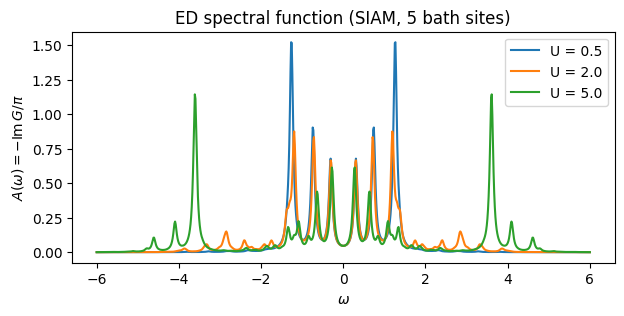

last solve: E0 = -6.2837, <n_imp> = 1.000, GS 1.5 ms, GF 60.0 ms


In [3]:
ed = EDSolver(aim)
w = np.linspace(-6, 6, 800) + 0.05j
fig, ax = plt.subplots(figsize=(7, 3))
for U in (0.5, 2.0, 5.0):
    G, E0, n_imp, t_gs, t_gf = ed.solve(U, 0.0, bath, w)
    ax.plot(w.real, -G[0].imag / np.pi, label=f"U = {U}")
ax.set(xlabel=r"$\omega$", ylabel=r"$A(\omega) = -\mathrm{Im}\,G/\pi$", title="ED spectral function (SIAM, 5 bath sites)")
ax.legend(); plt.show()
print(f"last solve: E0 = {E0:.4f}, <n_imp> = {n_imp[0]:.3f}, GS {t_gs * 1e3:.1f} ms, GF {t_gf * 1e3:.1f} ms")

## 2. Offline stage: building the ROM

`build` does three things:

1. **Greedy EC basis.**  From a Sobol grid of `ec_grid_size` candidate points
   $(U, J, \text{bath})$, it repeatedly solves the candidate with the largest Hamiltonian variance
   $\mathrm{Var}(\vec p) = \langle \mathcal H^2\rangle - \langle \mathcal H\rangle^2$ (evaluated in
   the reduced basis) and appends its ground state to $\mathcal B$, until the largest variance is
   below `ec_tol` ($\varepsilon_\mathrm{off}$).
2. **Interpolation frequencies.**  `r` Matsubara frequencies ($n = 0, 1$, then log-spaced up to
   `n_matsubara_max`); `frequencies="irka"` picks real-axis points by IRKA instead.
3. **Projections.**  For each orbital, $\mathbf V_p$ and $\mathbf V_h$ span the resolvent snapshots
   of the reference Hamiltonian $\mathcal H_0$ at the centre of the domain.

The result is an **atlas** directory holding one **patch** (the ROM).  Here $U \in [0.01, 6]$,
$r = 6$ and $\varepsilon_\mathrm{off} = 10^{-6}$; the paper's larger models used $r = 3$ and
$\varepsilon_\mathrm{off} = 10^{-2}$.

In [4]:
cfg = BuildConfig(N=6, NI=1, r=6, U_lo=0.01, U_hi=6.0, ec_tol=1e-6, ec_grid_size=256, n_workers=2)
t0 = time.perf_counter()
atlas = build(cfg, WORK / "atlas", verbose=False)
print(f"built in {time.perf_counter() - t0:.1f} s")

patch = atlas.patches[0]
patch.load()
d_gs, d_p = aim.basis["gs"].size, aim.basis["p"].size
m_p, m_h = patch.meta["m"]["0,0"]
print(f"EC basis   k = {patch.B.shape[1]}   (d_GS = {d_gs})")
print(f"ROM order  m_p = {m_p}, m_h = {m_h}   (d_p = d_h = {d_p})")
print("frequencies z_i =", np.round(patch.omega, 4))
print(f"reference  U_c = {patch.U_c:.3f}, E_c = {patch.E_c:.4f}")

built in 1.0 s
EC basis   k = 30   (d_GS = 400)
ROM order  m_p = 86, m_h = 86   (d_p = d_h = 300)
frequencies z_i = [0.+0.0135j 0.+0.0406j 0.+0.0677j 0.+0.149j  0.+0.4198j 0.+1.0968j]
reference  U_c = 3.005, E_c = -5.5369


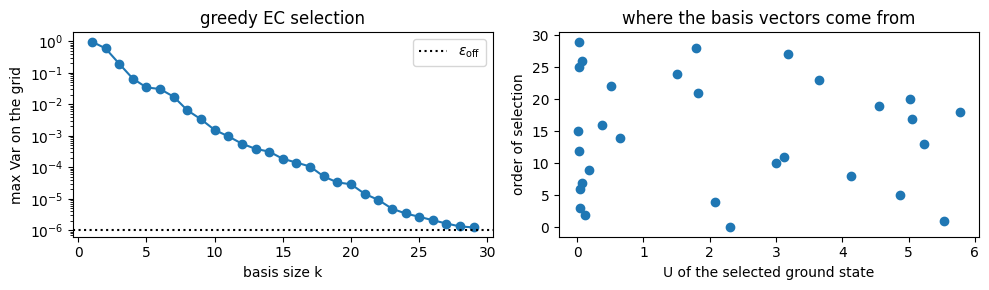

files in the patch: ['B.npz', 'V_h_0_0.npz', 'V_p_0_0.npz', 'h_r.npz', 'meta.json', 'pair_0_0.npz']


In [5]:
samples = atlas.config["global_ec"]["samples"]      # the exact solves the greedy loop chose
var = [s["variance"] for s in samples[1:]]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].semilogy(np.arange(1, len(var) + 1), var, "o-")
ax[0].axhline(cfg.ec_tol, color="k", ls=":", label=r"$\varepsilon_\mathrm{off}$")
ax[0].set(xlabel="basis size k", ylabel="max Var on the grid", title="greedy EC selection"); ax[0].legend()
ax[1].plot([s["U"] for s in samples], range(len(samples)), "o")
ax[1].set(xlabel="U of the selected ground state", ylabel="order of selection", title="where the basis vectors come from")
plt.tight_layout(); plt.show()

print("files in the patch:", sorted(p.name for p in Path(patch.path).iterdir()))

## 3. How good is the EC ground state?

The reduced ground state solves $\mathbf h(\vec p)\varphi = E\varphi$ with
$\mathbf h(\vec p) = \sum_q p_q\mathbf h_q$ (`solve_reduced`).  The plot shows its energy error, its
fidelity with the exact state, and its Ritz residual $\|(\mathcal H - E_\mathrm{EC})\Psi_\mathrm{EC}\|$,
which needs no ED and whose square is the variance the greedy loop uses.  Outside the training
domain (shaded) the basis degrades, which online enrichment (Section 6) repairs.

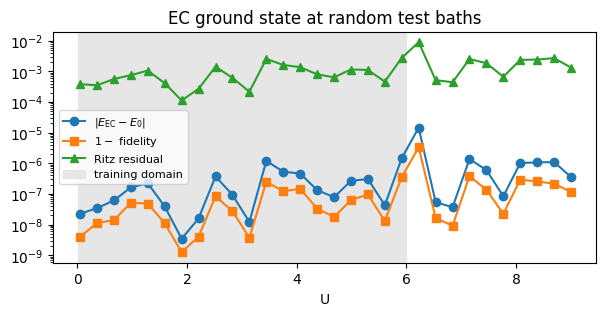

Var from reduced quantities = 1.702e-07
Ritz residual squared       = 1.702e-07


In [6]:
def ec_quality(U, bath):
    th = aim.theta(U, 0.0, bath)
    alpha, E_ec = solve_reduced(patch.h_r, th)
    psi_ec = patch.B @ alpha
    H = aim.hamiltonian("gs", th)
    E0, psi = canonical_gs(H)
    ritz = np.linalg.norm(H @ psi_ec - E_ec * psi_ec)
    return abs(E_ec - E0), (psi_ec @ psi) ** 2, ritz

Us = np.linspace(0.05, 9.0, 30)
test_baths = sample_baths(len(Us), NB=5, NI=1, base=base_bath(5, 1), scale=0.4, seed=7)
q = np.array([ec_quality(U, b) for U, b in zip(Us, test_baths)])

fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(Us, q[:, 0], "o-", label=r"$|E_\mathrm{EC} - E_0|$")
ax.semilogy(Us, 1 - q[:, 1], "s-", label=r"$1 - $ fidelity")
ax.semilogy(Us, q[:, 2], "^-", label="Ritz residual")
ax.axvspan(cfg.U_lo, cfg.U_hi, color="0.9", zorder=0, label="training domain")
ax.set(xlabel="U", title="EC ground state at random test baths"); ax.legend(fontsize=8); plt.show()

# The greedy indicator is the squared Ritz residual, computed without leaving the reduced space:
_, h2 = h2_terms(patch.B, aim.ops["gs"], also_h_r=False)
th = aim.theta(Us[5], 0.0, test_baths[5])
print(f"Var from reduced quantities = {variance(patch.h_r, h2, [th])[0]:.3e}")
print(f"Ritz residual squared       = {q[5, 2] ** 2:.3e}")

## 4. The ROM Green's function

`MORSolver` loads the atlas and evaluates, per orbital,

$$G(z) \approx \tilde a^\dagger\big[\widetilde{\mathbf I}(z + E) - \widetilde{\mathcal H}(\vec p)\big]^{-1}\tilde b
+ \big(\text{hole term}\big), \qquad \widetilde{\mathcal H}(\vec p) = \sum_q p_q \widetilde{\mathbf H}_q,$$

with $E$ and $\varphi$ from the EC problem.  Its `solve` has the same signature and return values
as `EDSolver.solve`.

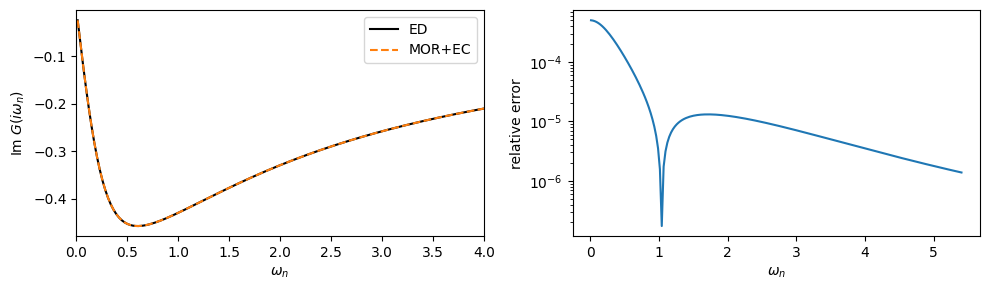

          ground state  Green function   total   (ms per solve)
ED                2.31            1.47    3.78


MOR+EC            0.05            0.71    0.76


In [7]:
rom = MORSolver(str(WORK / "atlas"))
U, bath_t = 3.3, test_baths[11]

G_ed = ed.solve(U, 0.0, bath_t, iw)[0][0]
G_rom = rom.solve(U, 0.0, bath_t, iw)[0][0]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(iw.imag, G_ed.imag, "k-", label="ED")
ax[0].plot(iw.imag, G_rom.imag, "C1--", label="MOR+EC")
ax[0].set(xlabel=r"$\omega_n$", ylabel=r"Im $G(i\omega_n)$", xlim=(0, 4)); ax[0].legend()
ax[1].semilogy(iw.imag, np.abs(G_rom - G_ed) / np.abs(G_ed))
ax[1].set(xlabel=r"$\omega_n$", ylabel="relative error"); plt.tight_layout(); plt.show()

def per_call(solver, n=20):
    """Mean (ground state, Green's function) seconds per solve; the first call is dropped."""
    t = np.array([solver.solve(U, 0.0, bath_t, iw)[3:] for _ in range(n + 1)])
    return t[1:].mean(axis=0)

print(f"{'':8s}{'ground state':>14s}{'Green function':>16s}{'total':>8s}   (ms per solve)")
for name, solver in (("ED", ed), ("MOR+EC", rom)):
    gs, gf = per_call(solver) * 1e3
    print(f"{name:8s}{gs:14.2f}{gf:16.2f}{gs + gf:8.2f}")

The ground state is where the ROM gains most: a $k\times k$ eigenproblem replaces a Lanczos run
in dimension $d_{GS}$.  The Green's function gains less at this size, because a Lanczos step costs
about $m^2$ operations for the ROM against $\mathrm{nnz}(\mathcal H)$ for ED (here 7,400 against
2,000).  Both shift in the ROM's favour as the impurity model grows.

The ROM was built from Matsubara-axis snapshots only, yet it also gives the real-frequency
spectrum, here to within a few percent of the peak height at $\eta = 0.05$.  The agreement worsens
as $\eta$ shrinks.

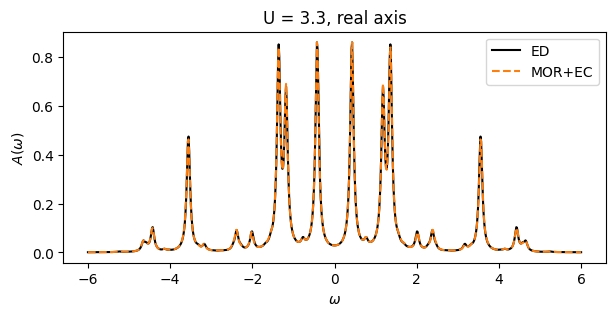

In [8]:
w = np.linspace(-6, 6, 800) + 0.05j
A_ed = -ed.solve(U, 0.0, bath_t, w)[0][0].imag / np.pi
A_rom = -rom.solve(U, 0.0, bath_t, w)[0][0].imag / np.pi
plt.figure(figsize=(7, 3))
plt.plot(w.real, A_ed, "k-", label="ED"); plt.plot(w.real, A_rom, "C1--", label="MOR+EC")
plt.xlabel(r"$\omega$"); plt.ylabel(r"$A(\omega)$"); plt.legend(); plt.title(f"U = {U}, real axis"); plt.show()

## 5. Self-energy and quasiparticle weight

With the bath hybridization $\Delta(i\omega_n) = \sum_b V_b^2/(i\omega_n - \varepsilon_b)$, Dyson's
equation gives $\Sigma = i\omega_n + \mu - \Delta - G^{-1}$ and the quasiparticle weight
$Z = [1 - \mathrm{Im}\,\Sigma(i\omega_0)/\omega_0]^{-1}$.

$Z$ is the most demanding test: $\Delta(i\omega_0)$ nearly cancels $G^{-1}$, so a small error in
$G$ is amplified in $\Sigma(i\omega_0)$ and again by $1/\omega_0$.  At an arbitrary test bath $Z$
can be far off even when $G(i\omega_0)$ is accurate to better than $10^{-3}$.  What matters in
practice is $Z$ at DMFT fixed points (Section 7), where enrichment tightens the ROM.

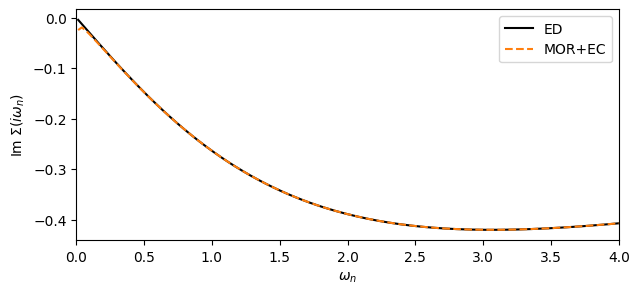

Z (ED    ) = 0.76400
Z (MOR+EC) = 0.35642
relative error of G(iw_0): 5.0e-04


In [9]:
eb, vb = full_bath(bath_t, NBpNI=5)
Delta = hybridization(eb[0], vb[0], iw)
mu = mu_half_filling(U, 0.0, NI=1)
Sigma = {name: iw + mu - Delta - 1 / G for name, G in (("ED", G_ed), ("MOR+EC", G_rom))}

plt.figure(figsize=(7, 3))
for (name, S), style in zip(Sigma.items(), ("k-", "C1--")):
    plt.plot(iw.imag, S.imag, style, label=name)
plt.xlim(0, 4); plt.xlabel(r"$\omega_n$"); plt.ylabel(r"Im $\Sigma(i\omega_n)$"); plt.legend(); plt.show()
for name, S in Sigma.items():
    print(f"Z ({name:6s}) = {quasiparticle_weight(S, iw):.5f}")
print(f"relative error of G(iw_0): {abs(G_rom[0] - G_ed[0]) / abs(G_ed[0]):.1e}")

## 6. Online enrichment

`MORSolver(..., enrich=EnrichConfig())` checks the Ritz residual of the reduced ground state.  If it
exceeds `tol` ($\varepsilon_\mathrm{trig}$), the solver

1. samples a small local Sobol grid around the current point (bath and $U$ jittered by `scale`),
2. greedily adds exact ground states until the local variance is below `variance_tol` ($\varepsilon_\mathrm{on}$),
3. extends every projector with resolvent snapshots on the new vectors, and saves the patch.

Enrichment **modifies the atlas on disk**, so work on a copy.  Here we ask for $U = 8.5$, outside
the training range.

In [10]:
shutil.copytree(WORK / "atlas", WORK / "atlas_enriched")
rom_e = MORSolver(str(WORK / "atlas_enriched"), enrich=EnrichConfig(tol=1e-3, variance_tol=1e-6), log=print)

U_far, bath_far = 8.5, test_baths[3]
G_ref = ed.solve(U_far, 0.0, bath_far, iw)[0][0]
err = lambda: np.max(np.abs(rom_e.solve(U_far, 0.0, bath_far, iw)[0][0] - G_ref)) / np.max(np.abs(G_ref))

print(f"before: k = {rom_e.atlas.patches[0].meta['k']}, relative GF error {err():.2e}")
for event in range(3):
    grown = rom_e.try_enrich(U_far, 0.0, bath_far)   # None: residual already below tol
    if not grown:
        break
    print(f"  after event {event + 1}: k = {rom_e.nearest.B.shape[1]}, relative GF error {err():.2e}")
print("enrichment history:", [(h["n_added"], h["total_time_s"]) for h in rom_e.nearest.meta["enrichment_history"]])

before: k = 30, relative GF error 2.19e-04
  [enrich] Ritz residual 7.42e-03 > tol=1.0e-03 at U=8.500; k=30


  [enrich] 4 local candidate(s); k 30 -> 31 (0.07s)
  after event 1: k = 31, relative GF error 6.62e-07
enrichment history: [(1, 0.023)]


## 7. DMFT with the ROM as impurity solver

`run_point` runs one DMFT self-consistency loop on the Bethe lattice: solve the impurity, extract
$\Sigma$, compute the lattice Green's function, fit a new bath, and repeat until $\Sigma$ changes by
less than `conv_tol`.  `sweep` runs a grid of points, warm-starting each from its nearest finished
neighbour and skipping finished ones.  Each point writes `dmft_log.txt`, `dmft_metadata.json`,
`gf_sigma_current.npz` and `bath_history.npz` to `<outdir>/J<J>/U<U>/`.

Below, the same $U$ sweep with ED, with the ROM as built, and with a ROM that enriches itself along
the way.  DMFT walks to baths far from the training set, so the static ROM misses the fixed points;
the enriched one follows ED.

ED           sweep:   1.6 s


ROM, static  sweep:   1.1 s


MOR+EC       sweep:   4.2 s


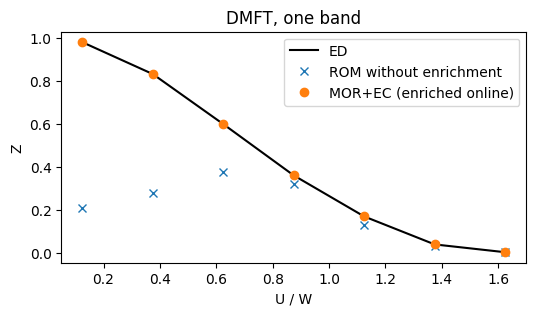

    U     Z ED  Z static  Z MOR+EC  ms/call ED ms/call MOR+EC
  0.5   0.9795    0.2093    0.9794        4.50           1.60
  1.5   0.8312    0.2784    0.8311        5.03           1.93
  2.5   0.5983    0.3755    0.5983        4.84           3.06
  3.5   0.3596    0.3204    0.3600        5.55           2.51
  4.5   0.1685    0.1309    0.1685        5.99           3.89
  5.5   0.0385    0.0313    0.0385        6.41           4.03
  6.5   0.0022    0.0031    0.0022        3.57           3.00
ROM basis after the enriching sweep: k = 80


In [11]:
def read_point(d):
    g = np.load(d / "gf_sigma_current.npz")
    iw_ = 1j * g["iw_imag"]
    meta = json.load(open(d / "dmft_metadata.json"))
    log = open(d / "dmft_log.txt").read()
    calls = np.array(re.findall(r"GS:\s*([\d.]+)s\s*GF:\s*([\d.]+)s", log), float)
    return dict(Z=[quasiparticle_weight(g["Sigma"][o], iw_, g["G_imp"][o], g["Delta"][o]) for o in range(len(g["Sigma"]))],
                n=float(re.findall(r"sum=([\d.]+)", log)[-1]), iters=meta["n_iter_done"],
                converged=meta["converged"], t_call=calls[1:].sum(axis=1).mean(), calls=calls)

dmft = DMFTConfig(N=6, NI=1, bw_ratios=[1.0], n_iter_max=80)
U_grid = sweep_values(0.5, 6.5, 1.0)
shutil.copytree(WORK / "atlas", WORK / "atlas_dmft")
enrich = EnrichConfig(tol=1e-3, variance_tol=1e-6)
solvers = {"ED": ed,
           "ROM, static": MORSolver(str(WORK / "atlas")),
           "MOR+EC": MORSolver(str(WORK / "atlas_dmft"), enrich=enrich, log=lambda *a: None)}
res = {}
for name, solver in solvers.items():
    t0 = time.perf_counter()
    out = WORK / ("dmft_" + name.replace(" ", "").replace(",", "_"))
    with quiet():
        sweep(dmft, solver, out, U_grid)
    res[name] = [read_point(out / "J0" / f"U{U:g}") for U in U_grid]
    print(f"{name:12s} sweep: {time.perf_counter() - t0:5.1f} s")

W = 4.0  # bandwidth (half-bandwidth 2)
plt.figure(figsize=(6, 3))
plt.plot(np.array(U_grid) / W, [r["Z"][0] for r in res["ED"]], "k-", label="ED")
plt.plot(np.array(U_grid) / W, [r["Z"][0] for r in res["ROM, static"]], "C0x", label="ROM without enrichment")
plt.plot(np.array(U_grid) / W, [r["Z"][0] for r in res["MOR+EC"]], "C1o", label="MOR+EC (enriched online)")
plt.xlabel("U / W"); plt.ylabel("Z"); plt.legend(); plt.title("DMFT, one band"); plt.show()
print(f"{'U':>5} {'Z ED':>8} {'Z static':>9} {'Z MOR+EC':>9}  {'ms/call ED':>10} {'ms/call MOR+EC':>14}")
for U, a, b, c in zip(U_grid, res["ED"], res["ROM, static"], res["MOR+EC"]):
    print(f"{U:5.1f} {a['Z'][0]:8.4f} {b['Z'][0]:9.4f} {c['Z'][0]:9.4f}  {a['t_call'] * 1e3:10.2f} {c['t_call'] * 1e3:14.2f}")
print("ROM basis after the enriching sweep: k =", solvers["MOR+EC"].atlas.patches[0].meta["k"])

The enriching sweep takes longer than the ED sweep, because every enrichment event solves
full-size problems.  That cost is paid once; Section 9 shows it being repaid.

## 8. Doping

Pass absolute chemical potentials as `mu_vals` (default: half filling).  Away from half filling the
bath is fitted in full form automatically, and the ROM covers the shift through the affine `dmu`
term.  Below, the impurity occupation across a chemical-potential scan at $U = 3$, with the
enriched ROM of Section 7.

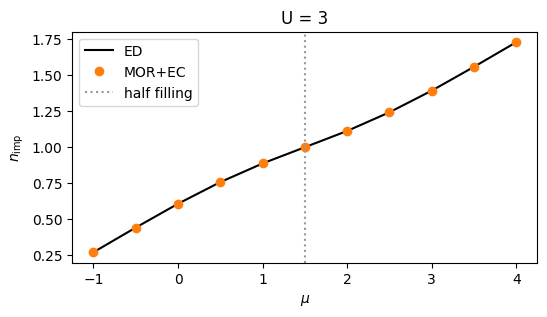

largest |n_ED - n_MOR| over the scan: 0.0000 (occupations are logged to 4 decimals)


In [12]:
mus = sweep_values(-1.0, 4.0, 0.5)
occ = {}
for name, solver in solvers.items():
    with quiet():
        sweep(dmft, solver, WORK / f"doping_{name}", [3.0], mu_vals=mus)
    occ[name] = [read_point(WORK / f"doping_{name}" / "J0" / "U3" / f"mu{m:g}")["n"] for m in mus]
plt.figure(figsize=(6, 3))
plt.plot(mus, occ["ED"], "k-", label="ED"); plt.plot(mus, occ["MOR+EC"], "C1o", label="MOR+EC")
plt.axvline(1.5, color="0.6", ls=":", label="half filling")
plt.xlabel(r"$\mu$"); plt.ylabel(r"$n_\mathrm{imp}$"); plt.legend(); plt.title("U = 3"); plt.show()
print(f"largest |n_ED - n_MOR| over the scan: {np.max(np.abs(np.array(occ['ED']) - occ['MOR+EC'])):.4f}"
      " (occupations are logged to 4 decimals)")

## 9. Two orbitals: a fine scan, and where the ROM pays off

The same API handles `NI = 2`; `bw_lo`/`bw_hi` let the training baths cover a range of bandwidth
ratios $t_2/t_1$ for the second orbital.  This section runs the paper's workflow in miniature:

1. build a two-band ROM;
2. **pay for it once**: a coarse DMFT sweep (14 points) with enrichment on;
3. **use it many times**: a fine scan over $U$ at three bandwidth ratios (195 DMFT points, about
   1,900 impurity solves) with enrichment off, and the same scan with ED.

One of the three ratios, $t_2/t_1 = 0.35$, is never visited by the coarse sweep.

In [13]:
aim2 = AIM(8, 2)
cfg2 = BuildConfig(N=8, NI=2, r=3, U_lo=0.01, U_hi=6.0, bw_lo=[1.0, 0.1], bw_hi=[1.0, 0.75],
                   ec_tol=1e-2, ec_grid_size=256, n_workers=2)
t0 = time.perf_counter()
build(cfg2, WORK / "atlas_2band", verbose=False)
t_build = time.perf_counter() - t0

dmft2 = DMFTConfig(N=8, NI=2, bw_ratios=[1.0, 0.2], n_iter_max=80)
events = []   # the solver's enrichment messages: each event's line ends with its full wall time
rom2 = MORSolver(str(WORK / "atlas_2band"), bw_ratios=dmft2.bw_ratios, log=events.append,
                 enrich=EnrichConfig(tol=1e-2, variance_tol=1e-4))
t0 = time.perf_counter()
with quiet():
    sweep(dmft2, rom2, WORK / "two_band_coarse", sweep_values(0.5, 6.5, 1.0), bwr_vals=[0.2, 0.5])
t_coarse = time.perf_counter() - t0
done = [e for e in events if "->" in e]         # one line per completed event
t_enrich = sum(float(re.search(r"\(([\d.]+)s\)", e).group(1)) for e in done)

p2 = Atlas(str(WORK / "atlas_2band")).patches[0]
rom_cost = t_build + t_enrich
print(f"offline build        : {t_build:5.1f} s")
print(f"coarse sweep         : {t_coarse:5.1f} s, of which {t_enrich:.1f} s in {len(done)} enrichment events")
m2 = [m for pair in p2.meta["m"].values() for m in pair]
print(f"ROM after enrichment : k = {p2.meta['k']}, m = {min(m2)}-{max(m2)} per sector  (d_GS = {aim2.basis['gs'].size}, d_p = {aim2.basis['p'].size})")
print(f"cost of the ROM      : {rom_cost:5.1f} s  (build + enrichment events)")

offline build        :   1.1 s
coarse sweep         :  20.9 s, of which 17.5 s in 16 enrichment events
ROM after enrichment : k = 94, m = 267-267 per sector  (d_GS = 4900, d_p = 3920)
cost of the ROM      :  18.6 s  (build + enrichment events)


In [14]:
U_fine, ratios = sweep_values(0.1, 6.5, 0.1), [0.2, 0.35, 0.5]
two = {"ED": EDSolver(aim2), "MOR+EC": MORSolver(str(WORK / "atlas_2band"), bw_ratios=dmft2.bw_ratios)}
fine = {}
for name, solver in two.items():
    t0 = time.perf_counter()
    out = WORK / f"two_band_fine_{name}"
    with quiet():
        sweep(dmft2, solver, out, U_fine, bwr_vals=ratios)
    fine[name] = {(b, U): read_point(out / f"bwr{b:.4g}" / "J0" / f"U{U:.4g}") for b in ratios for U in U_fine}
    print(f"{name:7s} fine scan, {len(fine[name])} DMFT points: {time.perf_counter() - t0:5.1f} s wall time")

ED      fine scan, 195 DMFT points:  69.1 s wall time


MOR+EC  fine scan, 195 DMFT points:  27.8 s wall time


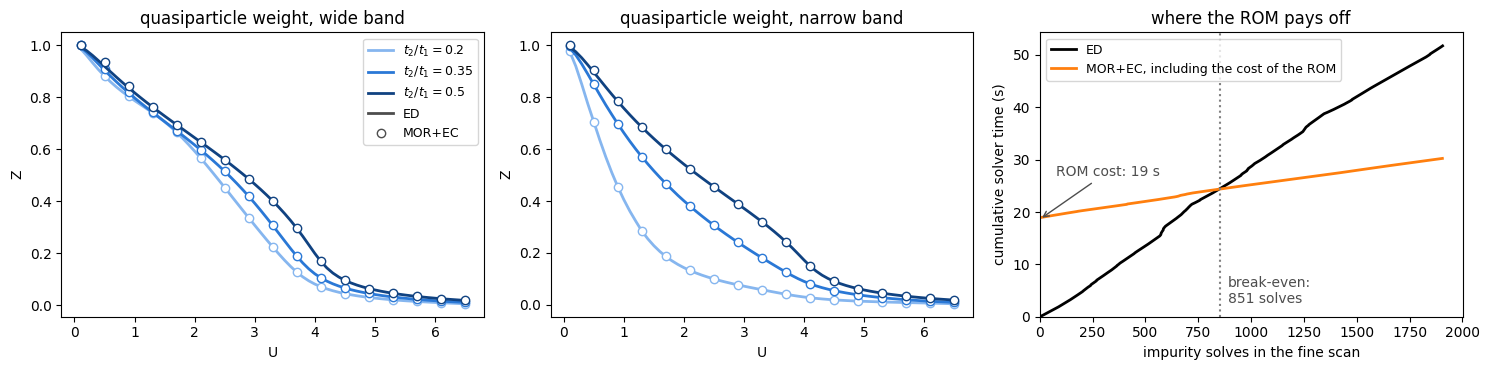

          ground state  Green function   total   (median ms per solve)
ED               16.80            8.60   25.50
MOR+EC            0.30            5.30    5.60

fine scan: ED 1906 solves, 51.7 s;  MOR+EC 1905 solves, 11.6 s + 18.6 s for the ROM = 30.2 s
break-even after 851 solves
t2/t1 = 0.2 : |Z_MOR - Z_ED| median 2.2e-06, max 1.3e-02
t2/t1 = 0.35: |Z_MOR - Z_ED| median 2.9e-05, max 1.4e-02
t2/t1 = 0.5 : |Z_MOR - Z_ED| median 6.6e-05, max 2.1e-02


In [15]:
from matplotlib.lines import Line2D

# (ground state, Green's function) seconds of every impurity solve, in the order of the scan
calls = {name: np.concatenate([pt["calls"] for pt in fine[name].values()]) for name in fine}
t_ed, t_rom = calls["ED"].sum(axis=1), calls["MOR+EC"].sum(axis=1)
cum_ed, cum_rom = np.cumsum(t_ed), rom_cost + np.cumsum(t_rom)
n = min(len(t_ed), len(t_rom))
ahead = np.nonzero(cum_rom[:n] < cum_ed[:n])[0]
n_even = int(ahead[0]) + 1 if ahead.size else None

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
shades = ["#86b6ef", "#2a78d6", "#104281"]
for o, title in ((0, "wide band"), (1, "narrow band")):
    for b, c in zip(ratios, shades):
        ax[o].plot(U_fine, [fine["ED"][(b, U)]["Z"][o] for U in U_fine], "-", color=c, lw=2)
        ax[o].plot(U_fine[::4], [fine["MOR+EC"][(b, U)]["Z"][o] for U in U_fine[::4]], "o", color=c, mfc="white", ms=6)
    ax[o].set(xlabel="U", ylabel="Z", title=f"quasiparticle weight, {title}")
ax[0].legend(handles=[Line2D([], [], color=c, lw=2, label=f"$t_2/t_1 = {b:g}$") for b, c in zip(ratios, shades)]
             + [Line2D([], [], color="0.3", lw=2, label="ED"),
                Line2D([], [], color="0.3", marker="o", mfc="white", ls="", label="MOR+EC")], fontsize=9)

ax[2].plot(np.arange(1, len(cum_ed) + 1), cum_ed, "k-", lw=2, label="ED")
ax[2].plot(np.arange(1, len(cum_rom) + 1), cum_rom, "C1-", lw=2, label="MOR+EC, including the cost of the ROM")
ax[2].annotate(f"ROM cost: {rom_cost:.0f} s", xy=(0, rom_cost), xytext=(0.04 * n, rom_cost + 0.16 * cum_ed[-1]),
               color="0.3", arrowprops=dict(arrowstyle="->", color="0.3"))
if n_even:
    ax[2].axvline(n_even, color="0.5", ls=":")
    ax[2].text(n_even + 0.02 * n, 0.05 * cum_ed[-1], f"break-even:\n{n_even} solves", color="0.3")
ax[2].set(xlabel="impurity solves in the fine scan", ylabel="cumulative solver time (s)",
          title="where the ROM pays off", xlim=(0, None), ylim=(0, None))
ax[2].legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

ms = lambda a: 1e3 * np.median(a)
print(f"{'':8s}{'ground state':>14s}{'Green function':>16s}{'total':>8s}   (median ms per solve)")
for name in fine:
    print(f"{name:8s}{ms(calls[name][:, 0]):14.2f}{ms(calls[name][:, 1]):16.2f}{ms(calls[name].sum(axis=1)):8.2f}")
print(f"\nfine scan: ED {len(t_ed)} solves, {cum_ed[-1]:.1f} s;  MOR+EC {len(t_rom)} solves, {t_rom.sum():.1f} s "
      f"+ {rom_cost:.1f} s for the ROM = {cum_rom[-1]:.1f} s")
print(f"break-even after {n_even} solves" if n_even else "no break-even within this scan")
for b in ratios:
    dZ = np.array([np.abs(np.subtract(fine["MOR+EC"][(b, U)]["Z"], fine["ED"][(b, U)]["Z"])) for U in U_fine
                   if fine["ED"][(b, U)]["converged"] and fine["MOR+EC"][(b, U)]["converged"]])
    print(f"t2/t1 = {b:<4g}: |Z_MOR - Z_ED| median {np.median(dZ):.1e}, max {dZ.max():.1e}")

The ROM reproduces the ED quasiparticle weights across the scan, including at $t_2/t_1 = 0.35$;
the largest differences, of order $10^{-2}$, are at the smallest $U$.

In the right panel MOR+EC starts with a debt, the offline build plus the enrichment events, and
repays it on every solve.  After the break-even every further solve is a net saving, so the
advantage grows with the length of the scan, and with the size of the impurity model.  The panel
counts solver time only; the bath fits and the rest of the DMFT loop are the same for both solvers.

## 10. Compressing the ROM

The ROM holds a snapshot for every basis state at every interpolation frequency, but a scan drives
only part of it.  `compress` keeps the directions the ROM's solutions used at the baths a finished
sweep visited (here the coarse sweep of Section 9), which shrinks $m$ and with it the cost of
every Green's function.  The compressed ROM serves Matsubara frequencies in the region that sweep
covered: calls at other frequencies still go through the full ROM, the ground state is unchanged,
and an enrichment event restores the full ROM.

Below, the $t_2/t_1 = 0.35$ part of the fine scan again, with the compressed ROM.


In [16]:
rom_c = MORSolver(str(WORK / "atlas_2band"), bw_ratios=dmft2.bw_ratios)
t0 = time.perf_counter()
sizes = rom_c.compress(WORK / "two_band_coarse", tol=1e-5)      # in memory; the atlas on disk is untouched
t_compress = time.perf_counter() - t0
with quiet():
    sweep(dmft2, rom_c, WORK / "two_band_fine_compressed", U_fine, bwr_vals=[0.35])
scan = {"ED": [fine["ED"][(0.35, U)] for U in U_fine], "full ROM": [fine["MOR+EC"][(0.35, U)] for U in U_fine],
        "compressed ROM": [read_point(WORK / "two_band_fine_compressed" / "bwr0.35" / "J0" / f"U{U:.4g}") for U in U_fine]}

m_c = [m for sectors in sizes.values() for m in sectors.values()]
gf_ms = {name: 1e3 * np.median(np.concatenate([pt["calls"][:, 1] for pt in pts])) for name, pts in scan.items()}
print(f"compression: {t_compress:.1f} s, m = {min(m2)}-{max(m2)} -> {min(m_c)}-{max(m_c)} per sector\n")
print(f"{'':16s}{'GF, ms per solve':>18s}{'|Z - Z_ED| median':>20s}{'max':>10s}")
for name, pts in scan.items():
    dZ = np.array([np.abs(np.subtract(a["Z"], b["Z"])) for a, b in zip(pts, scan["ED"]) if a["converged"] and b["converged"]])
    print(f"{name:16s}{gf_ms[name]:18.2f}" + (f"{np.median(dZ):20.1e}{dZ.max():10.1e}" if name != "ED" else ""))
print(f"\nthe compression is repaid after {1e3 * t_compress / (gf_ms['full ROM'] - gf_ms['compressed ROM']):.0f} solves")


compression: 10.0 s, m = 267-267 -> 98-104 per sector

                  GF, ms per solve   |Z - Z_ED| median       max
ED                            8.70
full ROM                      5.20             2.9e-05   1.4e-02
compressed ROM                2.10             8.2e-05   1.2e-02

the compression is repaid after 3221 solves


The compressed ROM follows ED as closely as the full one, at a ratio the coarse sweep never visited.
Whether the compression pays depends on the length of the scan; the saving per solve grows with the
size of the ROM.  `compress(..., final_only=True)` trains on the last bath of each DMFT loop only,
which is much cheaper but needs a coarse sweep whose grid is dense in the region to be scanned.


## 11. Where to go next

**Command line.**  Every `BuildConfig`, `DMFTConfig` and `EnrichConfig` field is a flag:

```bash
morec build atlas --N 8 --NI 2 --r 3 --ec_tol 1e-2 --bw_lo 1 0.01 --bw_hi 1 0.75
morec dmft runs/coarse --N 8 --NI 2 --bw_ratios 1 0.1 --atlas atlas --U 0 10 1 --bwr 0.1 0.5 0.1 --enrich
morec dmft runs/fine   --N 8 --NI 2 --bw_ratios 1 0.1 --atlas atlas --U 0 8 0.1 --bwr 0.1 0.5 0.01 --compress runs/coarse
morec dmft runs/ed     --N 8 --NI 2 --bw_ratios 1 0.1 --solver ED --U 0 10 1 --bwr 0.1 0.5 0.1
```

**Paper campaigns.**  `campaigns/run_campaign.py` holds the settings of every campaign in the
paper; `paper/make_figures.py` regenerates the figures from the data in `paper/data`.

**Tuning.**
* The EC basis is controlled by `ec_tol` ($\varepsilon_\mathrm{off}$) offline and by
  `EnrichConfig.tol` ($\varepsilon_\mathrm{trig}$) and `variance_tol` ($\varepsilon_\mathrm{on}$)
  online; the resolvent by the number of frequencies `r`.  Tightening them grows $k$ and $m$, and
  with them the cost of every solve.
* For DMFT, run a first, coarse sweep with enrichment on (Section 7).
* For a long scan, compress the ROM on that sweep (Section 10).  A looser `tol` gives a smaller,
  faster ROM and a larger error.
* Check low-frequency quantities such as $Z$ against ED on a few points before trusting a new
  setting.
* Multi-patch atlases (`n_patches_*`, `k_local`) and off-diagonal Green's functions are untested
  and emit a warning.